# 02 — Exploratory Data Analysis
**Day 2 · Phase 1: Data Understanding**

### Objectives
Understand how each specification is distributed and how it relates to price, *before* cleaning, so cleaning
decisions on Day 3 are informed by what the data looks like.

### Approach
- EDA runs on the **raw data with types converted only** (price and camera strings → numbers). No rows are removed,
  so the anomalies found on Day 1 stay visible. Feature phones (battery < 2,600 mAh or display < 10 cm) are
  highlighted as their own segment because Day 1 showed their storage/RAM values are unreliable.
- Price is right-skewed, so many charts use a **log price axis**: equal distances then mean equal *percentage*
  differences, which keeps both ₹6k and ₹80k phones readable.
- **Spearman** (rank) correlation is used alongside Pearson because most specs take a few discrete values and
  relationships are monotonic rather than straight lines.

*Brand and processor vendor/tier used for grouping in this notebook come from `src/feature_engineering.py`, which is
written up fully on Day 4.*

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from src.data_loader import load_raw_data
from src.preprocessing import RENAME_MAP, parse_price, parse_megapixels, is_feature_phone
from src.feature_engineering import extract_brand, processor_vendor, processor_tier

df = load_raw_data().drop(columns="Unnamed: 0").rename(columns=RENAME_MAP)
df["price"] = parse_price(df["price"])
df["rear_camera_mp"] = parse_megapixels(df["rear_camera_mp"])
df["front_camera_mp"] = parse_megapixels(df["front_camera_mp"])
df["brand"] = df["model"].map(extract_brand)
df["processor_vendor"] = [processor_vendor(p, b) for p, b in zip(df["processor"], df["brand"])]
df["processor_tier"] = [processor_tier(p, b) for p, b in zip(df["processor"], df["brand"])]
df["segment"] = np.where(is_feature_phone(df), "Feature phone", "Smartphone")

NUMERIC = ["storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp",
           "ai_lens", "display_size_cm", "price"]
print(df.shape)
print(df["segment"].value_counts().to_dict())

(541, 15)
{'Smartphone': 525, 'Feature phone': 16}


## 1. Univariate analysis
### 1.1 Price distribution

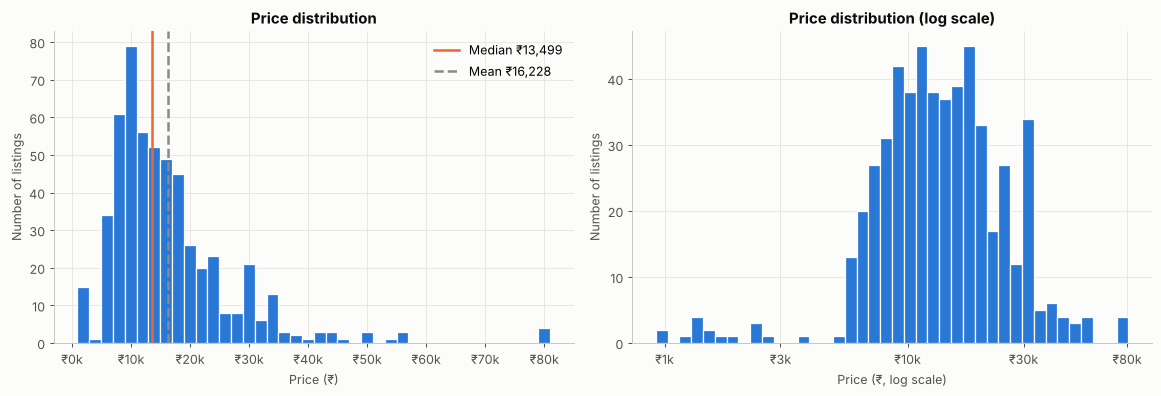

skewness (price)                2.426
skewness (log price)           -0.684
share of listings under ₹20k    0.771
dtype: float64

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df["price"], bins=40, color=PRIMARY, edgecolor="white")
axes[0].axvline(df["price"].median(), color=ACCENT, lw=2, label=f"Median ₹{df['price'].median():,.0f}")
axes[0].axvline(df["price"].mean(), color=NEUTRAL, lw=2, ls="--", label=f"Mean ₹{df['price'].mean():,.0f}")
axes[0].set(title="Price distribution", xlabel="Price (₹)", ylabel="Number of listings")
rupee_axis(axes[0], "x"); axes[0].legend()

axes[1].hist(np.log10(df["price"]), bins=40, color=PRIMARY, edgecolor="white")
ticks = [1000, 3000, 10000, 30000, 80000]
axes[1].set_xticks(np.log10(ticks), [f"₹{t/1000:.0f}k" for t in ticks])
axes[1].set(title="Price distribution (log scale)", xlabel="Price (₹, log scale)", ylabel="Number of listings")
fig.tight_layout(); save_fig(fig, "eda_price_distribution")

pd.Series({"skewness (price)": df["price"].skew(), "skewness (log price)": np.log(df["price"]).skew(),
           "share of listings under ₹20k": (df["price"] < 20000).mean()})

**Interpretation.** Prices are heavily right-skewed (skewness 2.43): most listings are budget/mid-range phones
between roughly ₹6k and ₹20k, with a long tail of premium phones up to ₹81k. On a log scale the distribution is much
more symmetric (skewness ≈ −0.68; the left tail is the ~₹1–3k feature phones). This supports **modelling log(price)**:
errors then become proportional (₹1,000 matters more on a ₹7k phone than on a ₹70k phone) and the few premium phones
stop dominating the loss.

### 1.2 Hardware specifications

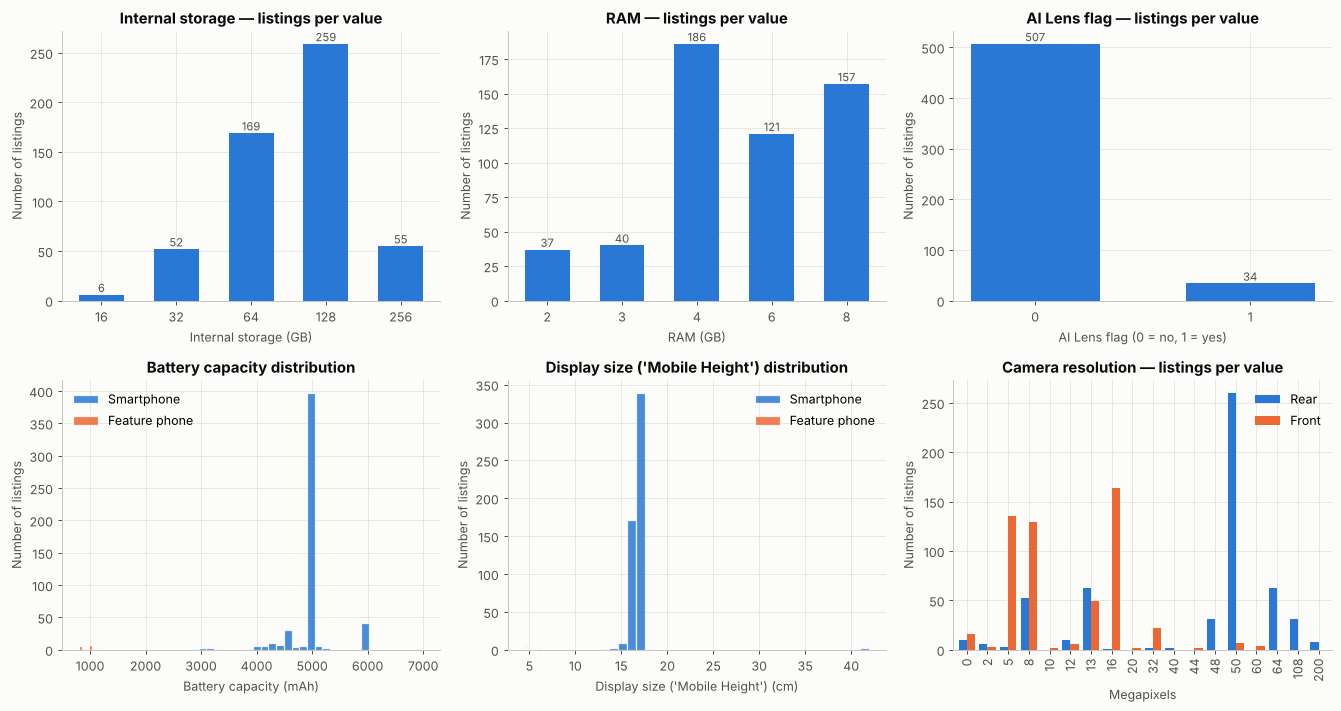

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col, title, unit in [
    (axes[0, 0], "storage_gb", "Internal storage", "GB"),
    (axes[0, 1], "ram_gb", "RAM", "GB"),
    (axes[0, 2], "ai_lens", "AI Lens flag", "0 = no, 1 = yes"),
]:
    counts = df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=PRIMARY, width=0.6)
    ax.set(title=f"{title} — listings per value", xlabel=f"{title} ({unit})", ylabel="Number of listings")
    for x, v in zip(counts.index.astype(str), counts.values):
        ax.text(x, v, f"{v}", ha="center", va="bottom", fontsize=9, color="#52514e")

for ax, col, title, unit in [
    (axes[1, 0], "battery_mah", "Battery capacity", "mAh"),
    (axes[1, 1], "display_size_cm", "Display size ('Mobile Height')", "cm"),
]:
    for seg, color in [("Smartphone", PRIMARY), ("Feature phone", ACCENT)]:
        ax.hist(df.loc[df["segment"] == seg, col], bins=30, color=color, alpha=0.85, label=seg, edgecolor="white")
    ax.set(title=f"{title} distribution", xlabel=f"{title} ({unit})", ylabel="Number of listings"); ax.legend()

cams = pd.DataFrame({"Rear": df["rear_camera_mp"].value_counts(), "Front": df["front_camera_mp"].value_counts()}).fillna(0).sort_index()
cams.plot.bar(ax=axes[1, 2], color=[PRIMARY, ACCENT], width=0.8)
axes[1, 2].set(title="Camera resolution — listings per value", xlabel="Megapixels", ylabel="Number of listings")
fig.tight_layout(); save_fig(fig, "eda_spec_distributions")

In [4]:
skew_table = pd.DataFrame({
    "skewness": df[NUMERIC].skew(),
    "min": df[NUMERIC].min(), "median": df[NUMERIC].median(), "max": df[NUMERIC].max(),
})
q1, q3 = df[NUMERIC].quantile(0.25), df[NUMERIC].quantile(0.75)
iqr = q3 - q1
skew_table["IQR outliers"] = ((df[NUMERIC] < q1 - 1.5 * iqr) | (df[NUMERIC] > q3 + 1.5 * iqr)).sum()
skew_table

,skewness,min,median,max,IQR outliers
storage_gb,1.030,16.000,128.000,256.000,55
ram_gb,0.068,2.000,6.000,8.000,0
battery_mah,-3.304,800.000,"5,000.000","7,000.000",152
rear_camera_mp,1.799,0.000,50.000,200.000,39
front_camera_mp,2.493,0.000,8.000,60.000,13
ai_lens,3.613,0.000,0.000,1.000,34
display_size_cm,1.172,4.500,16.710,41.940,33
price,2.426,920.000,"13,499.000","80,999.000",25


**Interpretation.**
- **Storage** clusters at 64 GB and 128 GB; **RAM** at 4/6/8 GB. Both are discrete and ordered — they behave like
  ordinal categories with a natural numeric order.
- **Battery**: 389 of 541 listings are exactly 5,000 mAh — the market standard. Because the distribution is a spike,
  the IQR rule flags 152 rows (every non-5,000 value), which shows **IQR “outliers” are not automatically errors**:
  the 4,000–4,500 mAh flagships and 6,000 mAh budget phones are real. The genuinely abnormal values (< 2,600 mAh) are
  all feature phones.
- **Display size**: smartphones sit tightly between ~15.5 and 17.6 cm; feature phones at 4.5–7 cm; two values at
  41.94 cm are the Day 1 entry error.
- **Cameras**: 50 MP dominates the rear camera; front cameras spread across 5/8/16 MP. `0 MP` (no camera) appears
  only on feature phones.
- **AI Lens** is rare (34 listings).

### 1.3 Processor, brand, model and colour

Distinct processor strings: 123
Distinct models: 187 | distinct colours: 275

Most listed models:
{'realme C55': 9, 'REDMI Note 12 Pro 5G': 9, 'vivo Y16': 9, 'SAMSUNG Galaxy A14 5G': 9, 'Infinix HOT 30i': 8}

Most common colours:
{'Yellow': 12, 'Royal Blue': 8, 'Power Black': 8, 'Black': 8, 'Cool Blue': 7, 'Midnight Black': 7, 'Glacier Blue': 6, 'Aqua Blue': 6}

Colours that appear only once: 137


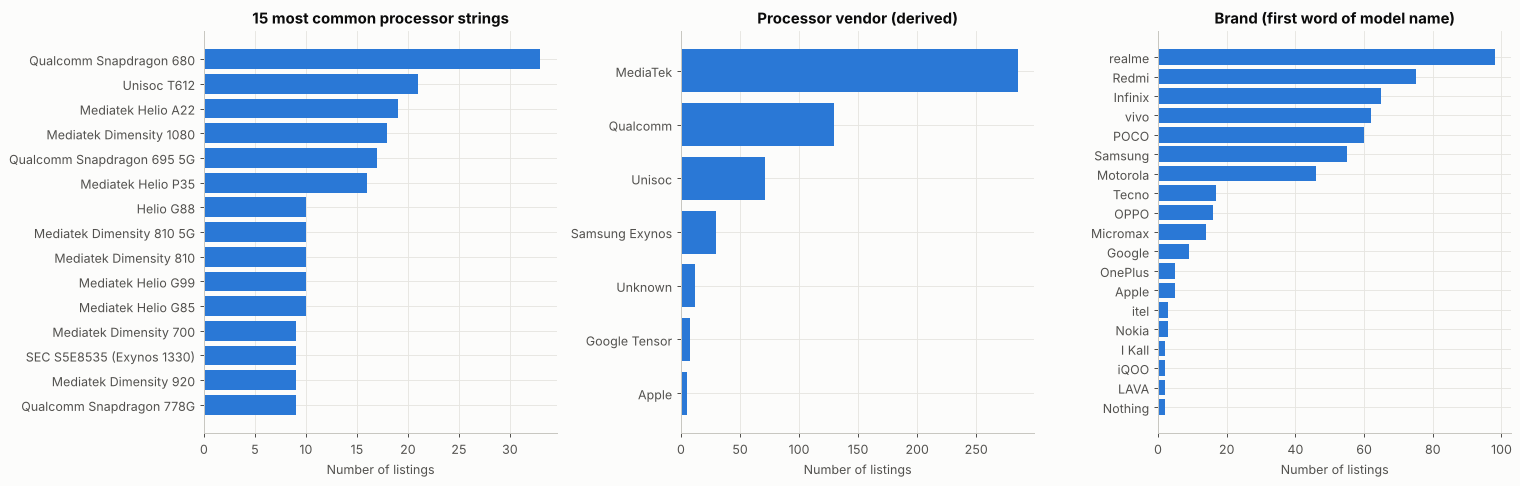

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
top_proc = df["processor"].value_counts().head(15).sort_values()
axes[0].barh(top_proc.index, top_proc.values, color=PRIMARY)
axes[0].set(title="15 most common processor strings", xlabel="Number of listings")

vendor = df["processor_vendor"].value_counts().sort_values()
axes[1].barh(vendor.index, vendor.values, color=PRIMARY)
axes[1].set(title="Processor vendor (derived)", xlabel="Number of listings")

brand = df["brand"].value_counts().sort_values()
axes[2].barh(brand.index, brand.values, color=PRIMARY)
axes[2].set(title="Brand (first word of model name)", xlabel="Number of listings")
fig.tight_layout(); save_fig(fig, "eda_categorical_distributions")

print("Distinct processor strings:", df["processor"].nunique())
print("Distinct models:", df["model"].nunique(), "| distinct colours:", df["colour"].nunique())
print("\nMost listed models:"); print(df["model"].value_counts().head(5).to_dict())
print("\nMost common colours:"); print(df["colour"].value_counts().head(8).to_dict())
print("\nColours that appear only once:", int((df["colour"].value_counts() == 1).sum()))

**Interpretation.**
- The 123 processor strings reduce to **6 vendors plus “Unknown”**. MediaTek (285 listings) and Qualcomm (130)
  dominate. The raw strings are too fragmented to use directly (the top string covers only 33 listings).
- **Brand coverage is uneven**: realme, Redmi, Infinix, vivo, POCO, Samsung and Motorola make up most listings,
  while Apple (5), Google (9), OnePlus (5), Nothing (2) and iQOO (2) are thin. The model will have very little evidence
  about premium brands, which is a key limitation for premium pricing.
- **Colour** is almost an identifier: 275 distinct values, many appearing once (*“Nebula Blue”*, *“Mineral Gray”*).
  Colour names are brand-specific marketing, so they cannot generalise to new phones.

## 2. Bivariate analysis — each specification vs price
### 2.1 Storage, RAM and AI Lens

storage_gb {16: 2624.0, 32: 6599.0, 64: 9990.0, 128: 16999.0, 256: 29999.0}
ram_gb {2: 6299.0, 3: 7994.5, 4: 9999.0, 6: 16499.0, 8: 21999.0}
ai_lens {0: 13999.0, 1: 8999.0}


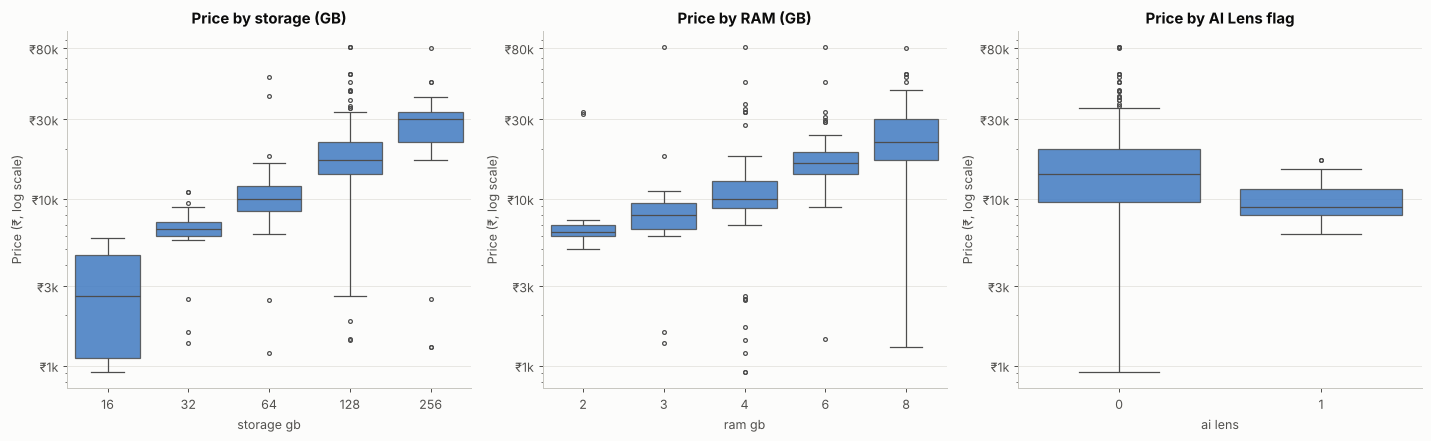

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, title in [(axes[0], "storage_gb", "Price by storage (GB)"), (axes[1], "ram_gb", "Price by RAM (GB)"),
                       (axes[2], "ai_lens", "Price by AI Lens flag")]:
    sns.boxplot(data=df, x=col, y="price", ax=ax, color=PRIMARY, fliersize=3, linewidth=1,
                boxprops=dict(alpha=0.85))
    ax.set_yscale("log"); ax.set_yticks([1000, 3000, 10000, 30000, 80000]); rupee_axis(ax)
    ax.set(title=title, xlabel=col.replace("_", " "), ylabel="Price (₹, log scale)")
fig.tight_layout(); save_fig(fig, "eda_price_by_storage_ram")

for col in ["storage_gb", "ram_gb", "ai_lens"]:
    print(col, df.groupby(col)["price"].median().to_dict())

**Interpretation.**
- **Storage** has the clearest staircase: median price roughly doubles with each step — ₹6.6k (32 GB) → ₹10k (64 GB)
  → ₹17k (128 GB) → ₹30k (256 GB). The 16 GB box is entirely feature phones.
- **RAM** shows the same monotonic pattern (₹6.3k at 2 GB → ₹22k at 8 GB) but with wider boxes at 6–8 GB, consistent
  with RAM being capped at 8 GB in this data (Day 1): premium phones with 12 GB are recorded lower.
- **AI Lens = 1 phones are cheaper** (median ₹9.0k vs ₹14.0k). This is not because an AI lens reduces value: the flag
  only appears on Infinix, a budget brand. It's a textbook **confounded** relationship.

### 2.2 Battery, display size and cameras

Median price by battery band (smartphones):
              count     median
battery_mah                   
(0, 4000]         8 27,344.000
(4000, 4500]     55 27,999.000
(4500, 4999]     20 31,936.500
(4999, 5000]    389 12,999.000
(5000, 5999]     10 21,086.000
(5999, 7000]     43  9,699.000

Median price by rear camera (smartphones):
rear_camera_mp       5         8          12        13        16         32         40         48         50         64         108        200
count              3.000    52.000     10.000    63.000     1.000      2.000      2.000     31.000    260.000     62.000     31.000      8.000
median         5,998.000 6,779.500 43,099.000 8,749.000 8,940.000 18,999.000 20,999.000 17,999.000 14,244.500 22,749.000 19,999.000 32,999.000


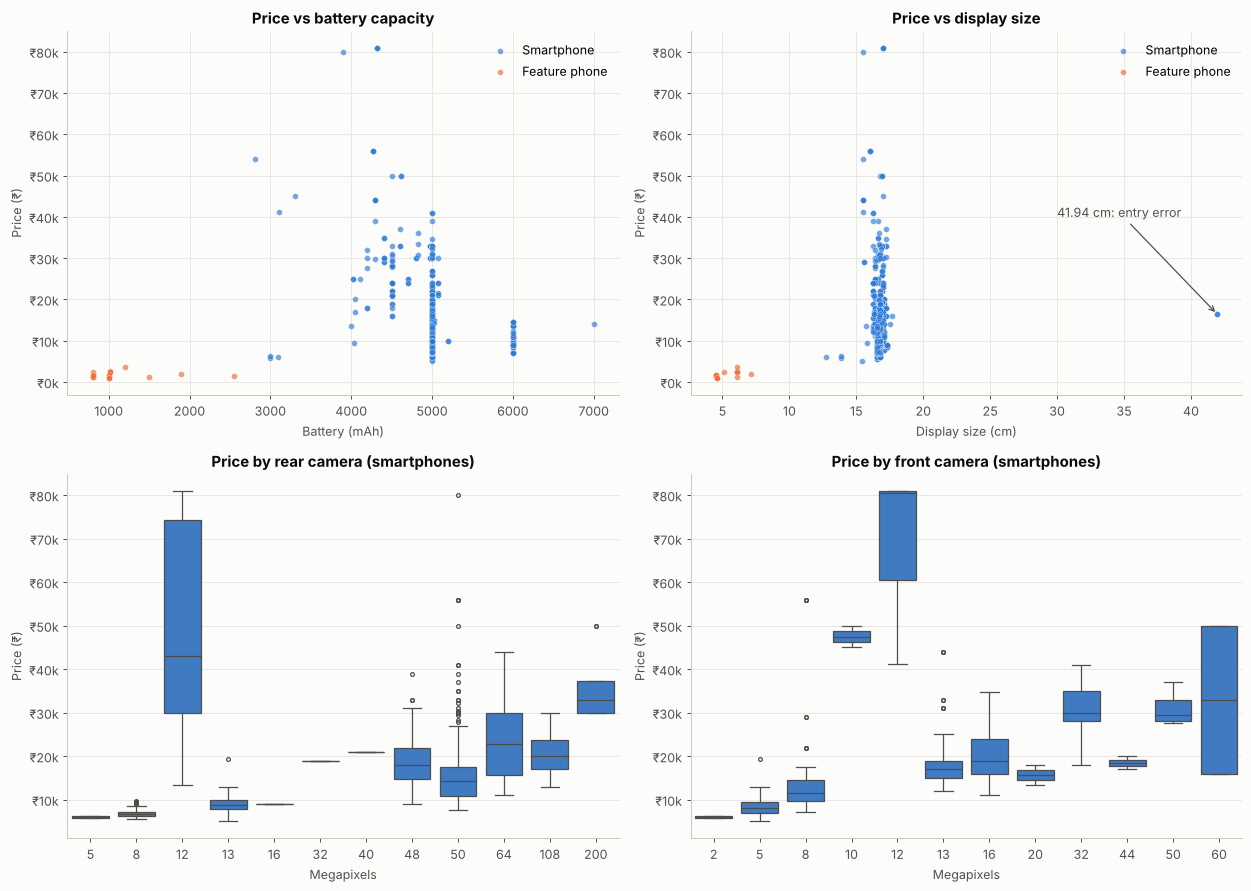

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for seg, color in [("Smartphone", PRIMARY), ("Feature phone", ACCENT)]:
    d = df[df["segment"] == seg]
    axes[0, 0].scatter(d["battery_mah"], d["price"], s=22, alpha=0.65, color=color, label=seg, edgecolor="white", linewidth=0.3)
    axes[0, 1].scatter(d["display_size_cm"], d["price"], s=22, alpha=0.65, color=color, label=seg, edgecolor="white", linewidth=0.3)
axes[0, 0].set(title="Price vs battery capacity", xlabel="Battery (mAh)", ylabel="Price (₹)")
axes[0, 1].set(title="Price vs display size", xlabel="Display size (cm)", ylabel="Price (₹)")
axes[0, 1].annotate("41.94 cm: entry error", xy=(41.94, 16499), xytext=(30, 40000),
                    arrowprops=dict(arrowstyle="->", color="#52514e"), color="#52514e")
for ax in axes[0]:
    rupee_axis(ax); ax.legend()

smart = df[df["segment"] == "Smartphone"]
for ax, col, title in [(axes[1, 0], "rear_camera_mp", "Price by rear camera (smartphones)"),
                       (axes[1, 1], "front_camera_mp", "Price by front camera (smartphones)")]:
    sns.boxplot(data=smart, x=col, y="price", ax=ax, color=PRIMARY, fliersize=3, linewidth=1)
    ax.set(title=title, xlabel="Megapixels", ylabel="Price (₹)"); rupee_axis(ax)
fig.tight_layout(); save_fig(fig, "eda_price_vs_battery_display_camera")

print("Median price by battery band (smartphones):")
print(smart.groupby(pd.cut(smart["battery_mah"], [0, 4000, 4500, 4999, 5000, 5999, 7000]), observed=True)["price"]
      .agg(["count", "median"]))
print("\nMedian price by rear camera (smartphones):")
print(smart.groupby("rear_camera_mp")["price"].agg(["count", "median"]).T)

**Interpretation.**
- **Battery is negatively associated with price among smartphones.** Phones with 4,000–4,500 mAh have a median of
  ~₹28k, 5,000 mAh ~₹13k, and 6,000 mAh+ ~₹9.7k. Large batteries are a *selling point of budget phones*, while
  premium phones prioritise thinner designs and faster charging. A battery doesn't make a phone cheaper; battery size
  marks the market segment.
- **Display size** is nearly flat for smartphones (almost all are 16.2–17.3 cm), so it is unlikely to explain much of
  the price.
- **Rear camera megapixels are not a quality score.** 12 MP phones have one of the highest medians (~₹43k) because
  they are iPhones and Pixels, while 50 MP is everywhere from ₹8k to ₹50k. The trend from 8 → 64 → 200 MP is upward,
  but with large exceptions.
- **Front camera** shows a cleaner upward trend (5 → 8 → 16 → 32/50 MP), plausibly because selfie-camera resolution
  is a feature brands upgrade together with the overall tier.

### 2.3 Processor and brand

              count     median
tier                          
0 Entry         167  8,288.000
1 Mainstream    250 14,999.000
2 Upper-mid      67 24,999.000
3 Flagship       41 32,999.000

Processor vendor:
                  count     median
processor_vendor                  
Unisoc               71  7,299.000
Unknown              12  7,999.000
MediaTek            285 12,499.000
Samsung Exynos       30 16,499.000
Qualcomm            130 17,999.000
Google Tensor         8 43,999.000
Apple                 5 80,999.000


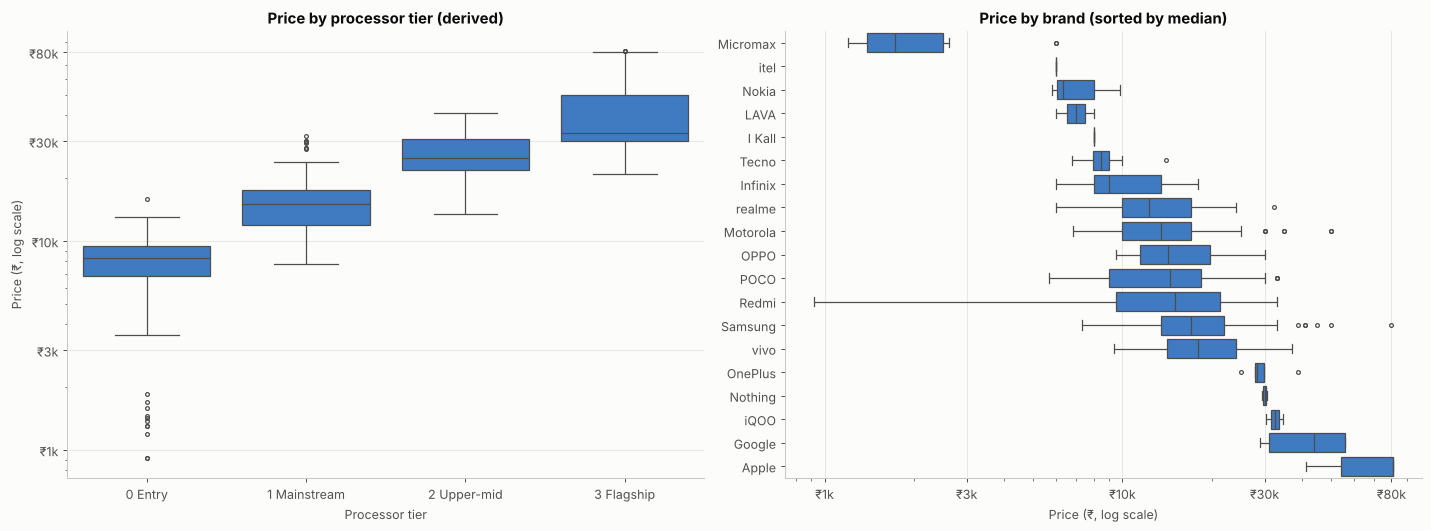

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
tier_labels = {0: "0 Entry", 1: "1 Mainstream", 2: "2 Upper-mid", 3: "3 Flagship"}
t = df.dropna(subset=["processor_tier"]).assign(tier=lambda d: d["processor_tier"].map(tier_labels))
sns.boxplot(data=t, x="tier", y="price", order=list(tier_labels.values()), ax=axes[0], color=PRIMARY, fliersize=3, linewidth=1)
axes[0].set_yscale("log"); axes[0].set_yticks([1000, 3000, 10000, 30000, 80000]); rupee_axis(axes[0])
axes[0].set(title="Price by processor tier (derived)", xlabel="Processor tier", ylabel="Price (₹, log scale)")

order = df.groupby("brand")["price"].median().sort_values().index
sns.boxplot(data=df, y="brand", x="price", order=order, ax=axes[1], color=PRIMARY, fliersize=3, linewidth=1)
axes[1].set_xscale("log"); axes[1].set_xticks([1000, 3000, 10000, 30000, 80000]); rupee_axis(axes[1], "x")
axes[1].set(title="Price by brand (sorted by median)", xlabel="Price (₹, log scale)", ylabel="")
fig.tight_layout(); save_fig(fig, "eda_price_by_processor_brand")

print(t.groupby("tier")["price"].agg(["count", "median"]))
print("\nProcessor vendor:"); print(df.groupby("processor_vendor")["price"].agg(["count", "median"]).sort_values("median"))

**Interpretation.**
- **Processor tier is one of the strongest price signals** — medians of ~₹8.3k (entry), ~₹15k (mainstream),
  ~₹25k (upper-mid) and ~₹33k (flagship), with little overlap between entry and flagship boxes. Extracting tier from
  messy chipset text looks worth the effort.
- **Brand** separates clearly: Micromax/itel/Nokia/Tecno/Infinix at the low end; realme/Motorola/POCO/Redmi/Samsung/
  vivo in the middle; OnePlus/Nothing/iQOO/Google/Apple at the top. Part of this is genuine brand premium, part is that
  brands specialise in tiers. The thin premium brands (2–9 listings) mean their medians are uncertain.

### 2.4 Model names

In [9]:
name = df["model"].str.lower()
flags = pd.DataFrame({
    "'5G' in name": name.str.contains(r"5\s*g\b"),
    "Pro / Plus / + / Ultra / Max / Fusion in name": name.str.contains(r"\b(?:pro|plus|ultra|max|fusion)\b|\+"),
})
rows = []
for col in flags:
    for val in [False, True]:
        sub = df[flags[col] == val]
        rows.append({"flag": col, "present": val, "listings": len(sub), "median price": sub["price"].median()})
pd.DataFrame(rows)

,flag,present,listings,median price
0,'5G' in name,False,347,"9,999.000"
1,'5G' in name,True,194,"19,739.000"
2,Pro / Plus / + / Ultra / Max / Fusion in name,False,451,"12,499.000"
3,Pro / Plus / + / Ultra / Max / Fusion in name,True,90,"21,499.000"


**Interpretation.** Model names carry useful information beyond the brand. Listings that advertise **5G** cost much
more (median ~₹19.7k vs ~₹10k), and names with **Pro / Plus / Ultra / Max** suffixes also sit higher (~₹21.5k vs ~₹12.5k). Both can be
extracted as binary features without using the model name as an identifier. (Note that “redmi max”, a feature phone,
is caught by the *Max* rule; it is excluded in cleaning.)

## 3. Multivariate analysis
### 3.1 Correlation heatmaps

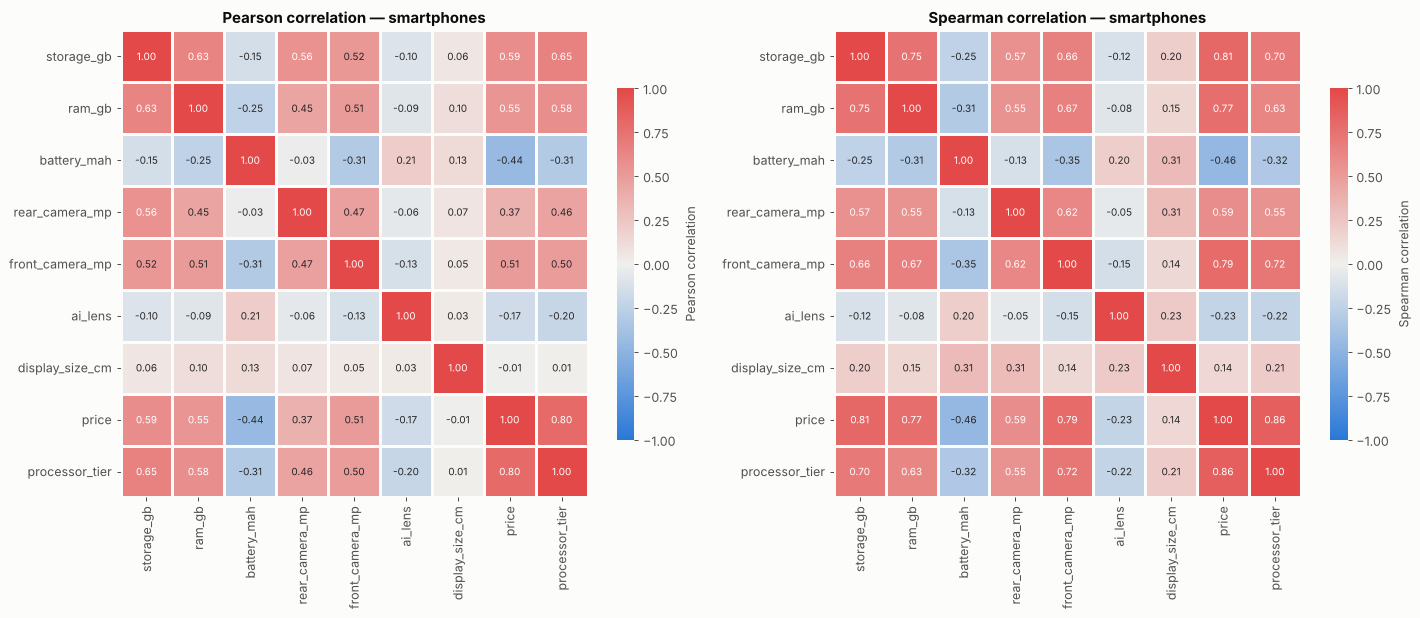

,pearson (all rows),spearman (all rows),spearman (smartphones)
battery_mah,-0.034,-0.299,-0.459
ai_lens,-0.154,-0.202,-0.226
display_size_cm,0.176,0.217,0.142
rear_camera_mp,0.410,0.626,0.588
ram_gb,0.532,0.734,0.767
front_camera_mp,0.532,0.810,0.792
storage_gb,0.567,0.769,0.808
processor_tier,NaN,NaN,0.860


In [10]:
smart_num = df.loc[df["segment"] == "Smartphone", NUMERIC + ["processor_tier"]]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = smart_num.corr(method=method)
    sns.heatmap(corr, ax=ax, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True,
                cbar_kws={"shrink": 0.75, "label": f"{method.title()} correlation"}, annot_kws={"size": 8},
                linewidths=1, linecolor="#fcfcfb")
    ax.set_title(f"{method.title()} correlation — smartphones"); ax.grid(False)
fig.tight_layout(); save_fig(fig, "eda_correlation_heatmap")

pd.DataFrame({"pearson (all rows)": df[NUMERIC].corr()["price"],
              "spearman (all rows)": df[NUMERIC].corr("spearman")["price"],
              "spearman (smartphones)": smart_num.corr("spearman")["price"]}).drop("price").sort_values("spearman (smartphones)")

**Interpretation.**
- Strongest monotonic relationships with price (smartphones, Spearman): **processor tier ≈ 0.86** (the derived
  feature is the single strongest), then **storage ≈ 0.81, front camera ≈ 0.79, RAM ≈ 0.77**, rear camera ≈ 0.59.
  Battery is **negative (≈ −0.46)**.
- Spearman is consistently higher than Pearson (e.g. storage 0.57 Pearson on all rows). The relationships are
  monotonic but not linear, and Pearson is pulled around by the premium tail. Using log(price) linearises many of them.
- Excluding feature phones *strengthens* the storage and RAM correlations. Their copied storage/RAM values
  (Day 1) were adding noise, which supports excluding them.
- **Multicollinearity:** storage, RAM, front camera and processor tier are all inter-correlated (0.6–0.75). They move
  together because manufacturers upgrade specs as a bundle. Feature-importance rankings will therefore split credit
  among them, which we must keep in mind on Days 6 and 10.

### 3.2 Pairwise relationships

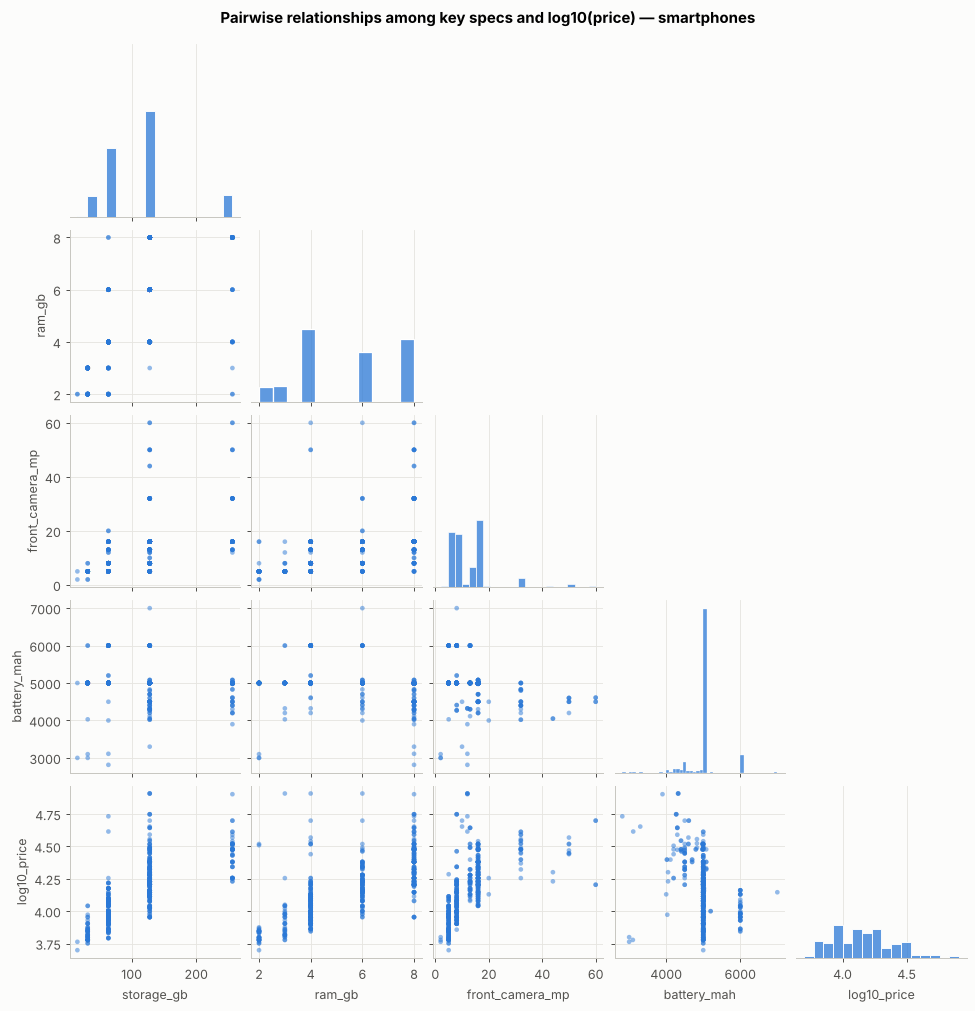

In [11]:
pair = df.loc[df["segment"] == "Smartphone", ["storage_gb", "ram_gb", "front_camera_mp", "battery_mah", "price"]].copy()
pair["log10_price"] = np.log10(pair.pop("price"))
g = sns.pairplot(pair, corner=True, plot_kws=dict(s=14, alpha=0.5, color=PRIMARY, edgecolor="none"),
                 diag_kws=dict(color=PRIMARY, edgecolor="white"), height=2.2)
g.figure.suptitle("Pairwise relationships among key specs and log10(price) — smartphones", y=1.02, fontweight="bold")
save_fig(g.figure, "eda_pairplot")

**Interpretation.** Against log price, storage, RAM and front camera each show a rising band of points, roughly
linear in log space. Battery points show the opposite drift. The discrete spec values create vertical stripes,
and the spread within each stripe is the variation that the other specs (processor, brand) must explain.

### 3.3 Price across combinations of specifications

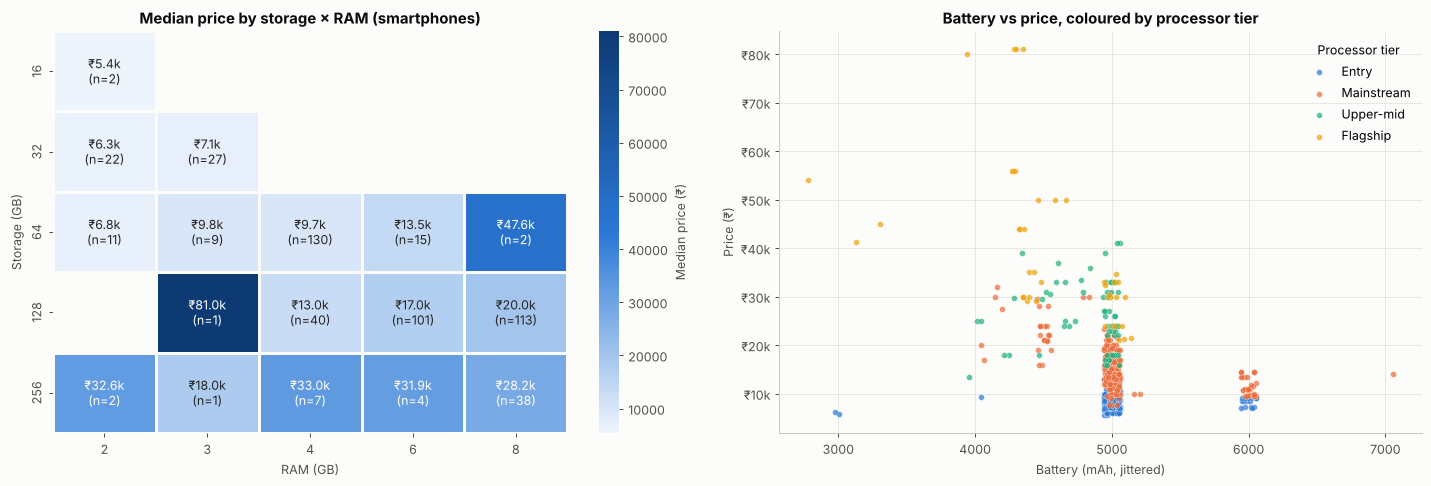

In [12]:
smart = df[df["segment"] == "Smartphone"]
pivot = smart.pivot_table(index="storage_gb", columns="ram_gb", values="price", aggfunc="median")
counts = smart.pivot_table(index="storage_gb", columns="ram_gb", values="price", aggfunc="count")
annot = pivot.map(lambda v: "" if pd.isna(v) else f"₹{v/1000:.1f}k") + counts.map(lambda v: "" if pd.isna(v) else f"\n(n={v:.0f})")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.heatmap(pivot, annot=annot, fmt="", cmap=SEQUENTIAL, ax=axes[0], cbar_kws={"label": "Median price (₹)"},
            linewidths=2, linecolor="#fcfcfb")
axes[0].set(title="Median price by storage × RAM (smartphones)", xlabel="RAM (GB)", ylabel="Storage (GB)"); axes[0].grid(False)

tier_labels = {0: "Entry", 1: "Mainstream", 2: "Upper-mid", 3: "Flagship"}
d = smart.dropna(subset=["processor_tier"]).assign(tier=lambda x: x["processor_tier"].map(tier_labels))
for i, (tier, color) in enumerate(zip(tier_labels.values(), PALETTE)):
    s = d[d["tier"] == tier]
    axes[1].scatter(s["battery_mah"] + np.random.default_rng(i).uniform(-60, 60, len(s)), s["price"],
                    s=22, alpha=0.7, color=color, label=tier, edgecolor="white", linewidth=0.3)
axes[1].set(title="Battery vs price, coloured by processor tier", xlabel="Battery (mAh, jittered)", ylabel="Price (₹)")
rupee_axis(axes[1]); axes[1].legend(title="Processor tier")
fig.tight_layout(); save_fig(fig, "eda_spec_combinations")

**Interpretation.**
- **Storage × RAM:** price rises along both axes; the top-right cells (128–256 GB with 8 GB) are the most expensive
  smartphones. Some cells are thin (n = 1–2) and look odd, e.g. 128 GB/3 GB at ₹81k is an iPhone whose RAM is
  unreliable (Day 1). Medians in tiny cells should not be over-read.
- **Battery vs tier:** flagship and upper-mid phones cluster at 4,000–4,800 mAh and high prices; entry phones cluster
  at 5,000–6,000 mAh and low prices. This confirms the negative battery–price correlation is driven by **market
  segment**: within one tier the battery effect is much weaker. A model that includes processor tier can separate
  these effects better than a single correlation can.

## 4. Summary of EDA findings
1. **Target:** right-skewed (2.43); log(price) is near-symmetric → model log price, report errors in rupees.
2. **Strongest associations:** processor tier (0.86), storage (0.81), front camera (0.79), RAM (0.77) — all positive,
   then rear camera. Brand separates price bands strongly.
3. **Counter-intuitive:** battery (negative) and AI Lens (negative) both reflect *segment/brand*, not value.
4. **Megapixels ≠ camera quality:** 12 MP iPhones/Pixels are among the most expensive phones.
5. **Display size** varies little among smartphones → likely weak predictor.
6. **Multicollinearity** among storage/RAM/front camera/tier → importance will be shared among them.
7. **Feature phones** behave as a different product category with unreliable storage/RAM → supports excluding them.
8. **IQR outliers** in battery (152 rows) are mostly normal market variation, not errors. Only display 41.94 cm and
   the feature-phone storage/RAM are real errors.
9. **Model names** contain usable signals (5G, Pro/Plus/Ultra); **colour** does not generalise.

These findings are also written up in `reports/eda_findings.md`.